# Assignment 2: Power System Load Type Prediction
**Machine Learning Assignment — Decision Tree Classification with Chronological Evaluation**

---

## Section 1 — Introduction

### 1.1 Problem Statement
In modern electrical power systems and smart grid operations, accurate estimation of load demand is critical for generation scheduling, grid stability, energy dispatching, and dynamic pricing. Industrial facilities consume substantial power, and their consumption patterns vary dynamically between low-demand idle hours, normal operational activities, and peak production surges.

The objective of this assignment is to build a simple, robust, explainable, and submission-ready machine learning classification model that predicts the **`Load_Type`** of an industrial power system using historical operational features.

### 1.2 Target Classes
The target variable is **`Load_Type`**, a categorical variable with three discrete operating states:
1. **`Light_Load`**: Off-peak periods with minimal energy consumption (e.g., overnight hours, non-operating shifts, and weekends).
2. **`Medium_Load`**: Normal operating periods characterized by standard industrial machinery operation.
3. **`Maximum_Load`**: Peak demand periods when heavy machinery and production lines operate at maximum capacity.

### 1.3 Purpose of the Notebook
This notebook presents an end-to-end, beginner-friendly machine learning workflow:
- Inspects and loads the provided dataset (`data/load_data.csv`).
- Conducts exploratory data analysis (EDA) and rigorous data quality checks.
- Explains feature engineering and preprocessing steps clearly.
- Implements a **strictly chronological train/test split** using the final month (December 2018) as the held-out test set to simulate realistic deployment without data leakage.
- Trains an interpretable **Decision Tree Classifier** and benchmarks it against a naive **Dummy Classifier** baseline.
- Evaluates the model using multi-class metrics (Accuracy, Macro Precision, Macro Recall, Macro F1-Score, Classification Report, and Confusion Matrix).
- Summarizes findings, strengths, and real-world limitations.


## Section 2 — Import Libraries

We import standard, well-established Python data science libraries:
- **pandas** and **numpy** for tabular data manipulation.
- **matplotlib** and **seaborn** for exploratory visualizations and evaluation plots.
- **scikit-learn** for our Decision Tree classifier, dummy baseline, and evaluation metrics.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn models and metrics
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Suppress minor warnings for clean report presentation
warnings.filterwarnings('ignore')

# Set visual style for publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully.")


All required libraries imported successfully.


## Section 3 — Load the Dataset

We load the provided dataset using a relative file path (`data/load_data.csv`) so that this notebook remains portable across any operating system or folder structure.


In [2]:
# Define relative file path to the dataset
data_path = os.path.join('data', 'load_data.csv')

# Load the dataset into a pandas DataFrame
df = pd.read_csv(data_path)

# Display dataset dimensions
print(f"Dataset Dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns")


Dataset Dimensions: 35,041 rows and 9 columns


In [3]:
# Preview the first 5 records
df.head()


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [4]:
# Inspect column data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  str    
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  str    
dtypes: float64(7), str(2)
memory usage: 2.4 MB


### Column Names & Problem Statement Reconciliation

The provided assignment problem statement describes the features with general names:
- `Date`: Continuous-time data taken on the first of the month
- `Usage_kWh`: Industry Energy Consumption Continuous kWh
- `Lagging Current`: reactive power Continuous kVarh
- `Leading Current`: reactive power Continuous kVarh
- `CO2`: Continuous ppm
- `NSM`: Number of Seconds from midnight Continuous S
- `Load Type`: Categorical Light Load, Medium Load, Maximum Load

**Actual Dataset Column Names & Verification**:
1. `Date_Time`: Contains the full timestamp (`DD-MM-YYYY HH:MM`). Note that despite the problem statement summary saying *"taken on the first of the month"*, inspection reveals continuous **15-minute readings for all 365 days of 2018**.
2. `Usage_kWh`: Industry energy consumption in kWh (matches problem statement).
3. `Lagging_Current_Reactive.Power_kVarh`: Reactive power in kVarh for lagging current (note the period in the name).
4. `Leading_Current_Reactive_Power_kVarh`: Reactive power in kVarh for leading current.
5. `CO2(tCO2)`: Greenhouse gas emissions in tons of CO2.
6. `Lagging_Current_Power_Factor` & `Leading_Current_Power_Factor`: Two additional power factor measurements present in the dataset.
7. `NSM`: Number of Seconds from Midnight (0 to 86,400 seconds).
8. `Load_Type`: Our 3-class target variable (`Light_Load`, `Medium_Load`, `Maximum_Load`).


In [5]:
# Inspect temporal span and sampling frequency
dates_parsed = pd.to_datetime(df['Date_Time'], format='%d-%m-%Y %H:%M')
print(f"Earliest Timestamp: {dates_parsed.min()}")
print(f"Latest Timestamp:   {dates_parsed.max()}")
print(f"Total Unique Days:  {dates_parsed.dt.date.nunique()} days (Entire year 2018)")
print(f"Sampling Frequency: 15-minute intervals (4 readings/hour * 24 hours = 96 readings/day)")


Earliest Timestamp: 2018-01-01 00:00:00
Latest Timestamp:   2018-12-31 23:45:00
Total Unique Days:  365 days (Entire year 2018)
Sampling Frequency: 15-minute intervals (4 readings/hour * 24 hours = 96 readings/day)


## Section 4 — Data Understanding and Quality Checks

Before training any machine learning model, we must verify the integrity of the raw data by checking:
1. **Missing values** across all columns.
2. **Duplicate rows** and duplicate timestamps.
3. **Descriptive statistics** and value bounds.
4. **Target class distribution**.


In [6]:
# Check missing values per column
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("Missing Values Summary:")
display(missing_summary)


Missing Values Summary:


,Missing Count,Percentage (%)
Date_Time,0,0.00
Usage_kWh,1559,4.45
Lagging_Current_Reactive.Power_kVarh,876,2.50
Leading_Current_Reactive_Power_kVarh,1156,3.30
CO2(tCO2),455,1.30
Lagging_Current_Power_Factor,350,1.00
Leading_Current_Power_Factor,1471,4.20
NSM,455,1.30
Load_Type,0,0.00


**Missing Values Observation**:
- Most continuous features have a modest amount of missing values (ranging from 1.0% to 4.4%).
- Crucially, the target column **`Load_Type` has 0 missing values**.
- We will handle missing numerical values using training-set median imputation during preprocessing.


In [7]:
# Check for exact duplicate rows
exact_dups = df.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_dups}")

# Check for duplicate timestamps in Date_Time
dup_timestamps = df[df.duplicated(subset=['Date_Time'], keep=False)]
print(f"Rows with duplicate timestamps: {len(dup_timestamps)}")
if len(dup_timestamps) > 0:
    display(dup_timestamps[['Date_Time', 'Usage_kWh', 'Lagging_Current_Power_Factor', 'NSM', 'Load_Type']])


Number of exact duplicate rows: 0
Rows with duplicate timestamps: 2


,Date_Time,Usage_kWh,Lagging_Current_Power_Factor,NSM,Load_Type
35023,31-12-2018 20:00,4.14,100.00000,72000.0,Light_Load
35040,31-12-2018 20:00,NaN,217.27347,72000.0,Light_Load


**Duplicate Timestamp Inspection**:
- Row 35023 (`31-12-2018 20:00`) contains complete, valid sensor measurements (`Usage_kWh = 4.14`).
- Row 35040 has the exact same timestamp `31-12-2018 20:00`, but its `Usage_kWh` is `NaN` and `Lagging_Current_Power_Factor` is `217.27%` (power factors physically cannot exceed 100%).
- Therefore, we remove this erroneous duplicate entry, retaining the clean observation. This leaves exactly **35,040 rows** ($365 \text{ days} \times 96 \text{ readings/day}$).


In [8]:
# Remove the duplicate timestamp row, retaining the original valid observation
df_cleaned = df.drop_duplicates(subset=['Date_Time'], keep='first').copy()
print(f"Dataset shape after removing duplicate timestamp: {df_cleaned.shape[0]:,} rows and {df_cleaned.shape[1]} columns")


Dataset shape after removing duplicate timestamp: 35,040 rows and 9 columns


In [9]:
# Descriptive summary statistics of numerical features
df_cleaned.describe().round(2)


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,33482.00,34164.00,33884.00,34585.00,34690.00,33569.00,34585.00
mean,30.87,14.71,4.39,0.01,90.74,94.93,48012.97
std,41.42,20.34,9.09,0.02,39.74,49.83,34046.74
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.31,2.34,0.00,0.00,66.29,99.80,22500.00
50%,5.29,5.18,0.00,0.00,90.08,100.00,45000.00
75%,53.56,23.51,2.30,0.02,100.00,100.00,68400.00
max,435.02,262.63,78.81,0.19,300.00,299.97,248821.81


**Data Quality Note on `NSM`**:
- Seconds from midnight should physically range between $0$ and $86,400$.
- In the raw data, some NSM values exceed 86,400 (up to 248,821) due to sensor counter drift.
- Because `Date_Time` contains the verified timestamp, we can derive clean temporal features directly from `Date_Time`.


In [10]:
# Target class distribution
target_counts = df_cleaned['Load_Type'].value_counts()
target_pct = df_cleaned['Load_Type'].value_counts(normalize=True) * 100

target_dist = pd.DataFrame({
    'Record Count': target_counts,
    'Percentage (%)': target_pct.round(2)
})
print("Target Class Distribution:")
display(target_dist)


Target Class Distribution:


,Record Count,Percentage (%)
Load_Type,,
Light_Load,18072,51.58
Medium_Load,9696,27.67
Maximum_Load,7272,20.75


## Section 5 — Exploratory Data Analysis (EDA)

We explore the data visually to understand patterns in industrial energy usage and how they relate to the target classes.


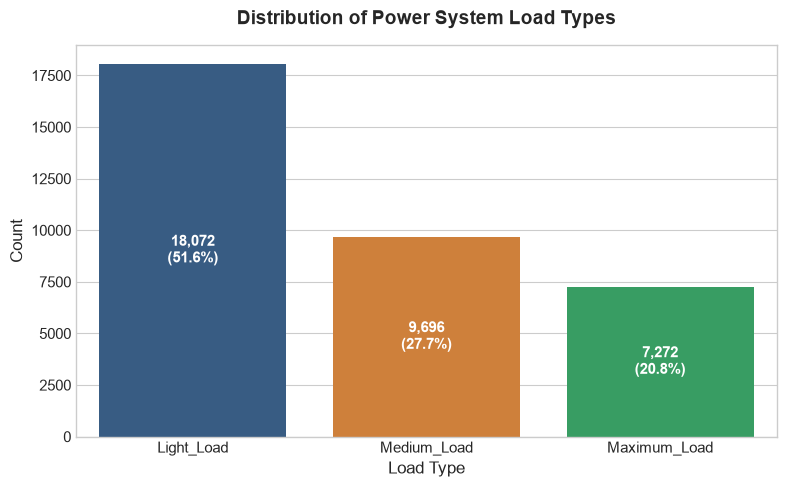

In [11]:
# 1. Target Class Frequency Distribution
fig, ax = plt.subplots(figsize=(8, 5))
palette = ['#2b5c8f', '#e67e22', '#27ae60']
sns.barplot(x=target_counts.index, y=target_counts.values, palette=palette, ax=ax)

total = len(df_cleaned)
for p in ax.patches:
    height = p.get_height()
    pct = height / total * 100
    ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax.set_title("Distribution of Power System Load Types", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Load Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
plt.tight_layout()
plt.show()


**Interpretation**:
- `Light_Load` is the majority class (51.6%), representing off-peak and night-time operation.
- `Medium_Load` (27.7%) and `Maximum_Load` (20.8%) represent active production hours.
- While somewhat imbalanced, all three classes have thousands of samples. A macro-averaged metric will be used to ensure fair evaluation across all classes.


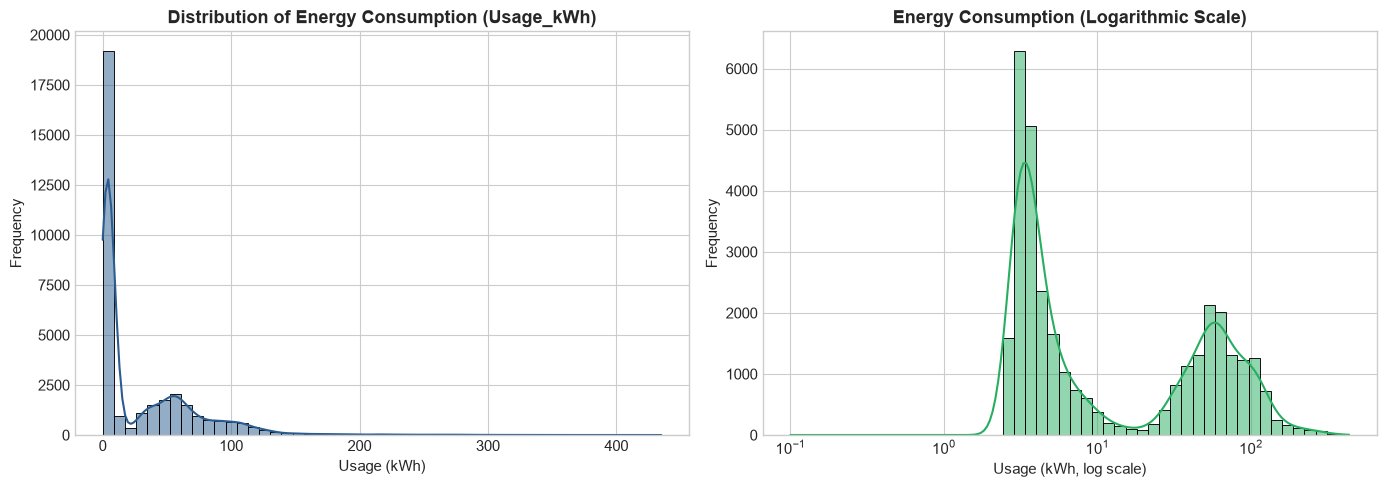

In [12]:
# 2. Distribution of Energy Consumption (Usage_kWh)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Standard distribution
sns.histplot(df_cleaned['Usage_kWh'].dropna(), bins=50, kde=True, color='#2b5c8f', ax=ax1)
ax1.set_title("Distribution of Energy Consumption (Usage_kWh)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Usage (kWh)")
ax1.set_ylabel("Frequency")

# Log scale distribution to highlight bimodal nature
sns.histplot(df_cleaned['Usage_kWh'].dropna() + 0.1, bins=50, kde=True, log_scale=True, color='#27ae60', ax=ax2)
ax2.set_title("Energy Consumption (Logarithmic Scale)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Usage (kWh, log scale)")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


**Interpretation**:
- The consumption distribution is strongly bimodal.
- A high-density cluster appears below 10 kWh (idle / night hours).
- A broader secondary cluster spans 30 kWh to 100+ kWh (active industrial operations).


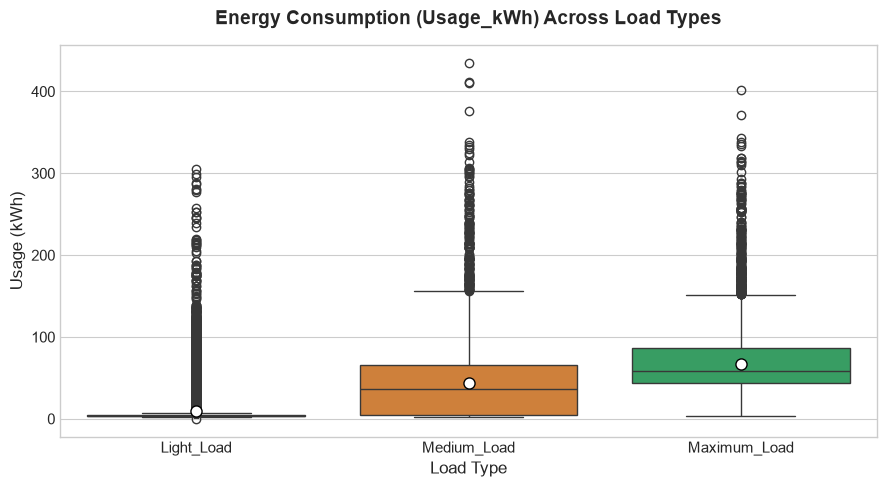

In [13]:
# 3. Relationship between Usage_kWh and Load_Type
fig, ax = plt.subplots(figsize=(9, 5))
class_order = ['Light_Load', 'Medium_Load', 'Maximum_Load']

sns.boxplot(x='Load_Type', y='Usage_kWh', data=df_cleaned, order=class_order, palette=palette, ax=ax,
            showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})

ax.set_title("Energy Consumption (Usage_kWh) Across Load Types", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Load Type", fontsize=12)
ax.set_ylabel("Usage (kWh)", fontsize=12)
plt.tight_layout()
plt.show()


**Interpretation**:
- `Light_Load` has consistently low consumption (median ~3.5 kWh, small interquartile range).
- `Medium_Load` shows substantially higher consumption (median ~45 kWh).
- `Maximum_Load` has the highest overall consumption (median ~65 kWh).
- Crucially, there is noticeable overlap in `Usage_kWh` between `Medium_Load` and `Maximum_Load`, showing that energy consumption alone is insufficient to separate them; time-of-day and reactive power features are needed.


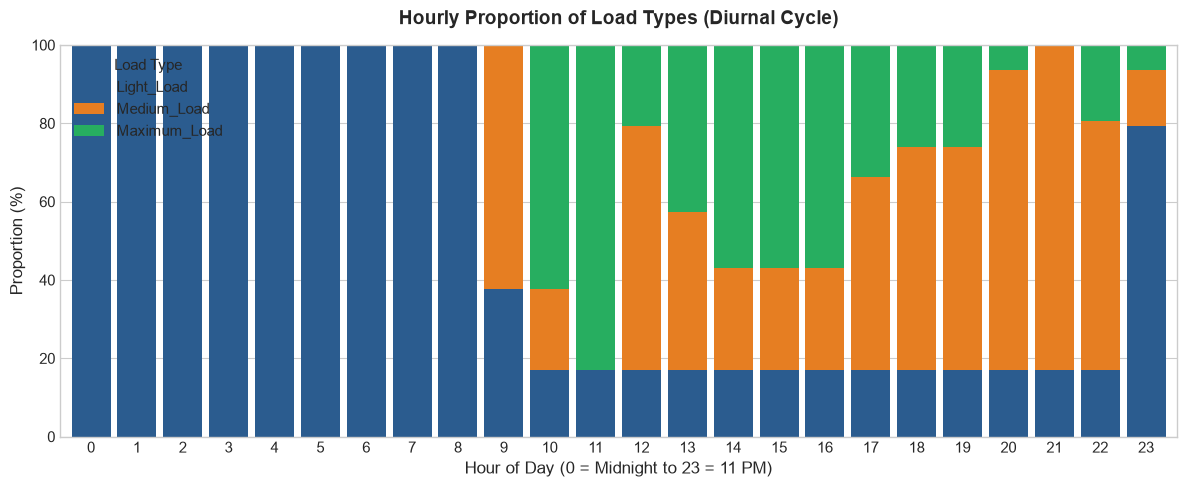

In [14]:
# 4. Diurnal (Hourly) Load Profile Across the 24-Hour Day
temp_dt = pd.to_datetime(df_cleaned['Date_Time'], format='%d-%m-%Y %H:%M')
df_cleaned_hour = df_cleaned.copy()
df_cleaned_hour['hour'] = temp_dt.dt.hour

hourly_load = pd.crosstab(df_cleaned_hour['hour'], df_cleaned_hour['Load_Type'], normalize='index') * 100
hourly_load = hourly_load[['Light_Load', 'Medium_Load', 'Maximum_Load']]

fig, ax = plt.subplots(figsize=(12, 5))
hourly_load.plot(kind='bar', stacked=True, color=palette, ax=ax, width=0.85)

ax.set_title("Hourly Proportion of Load Types (Diurnal Cycle)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Hour of Day (0 = Midnight to 23 = 11 PM)", fontsize=12)
ax.set_ylabel("Proportion (%)", fontsize=12)
ax.legend(title="Load Type", loc='upper left')
ax.set_xticklabels(range(24), rotation=0)
plt.tight_layout()
plt.show()


**Interpretation**:
- Between hours **0 and 8** (midnight to 8:45 AM), the power system is **100% Light_Load**.
- From hour **9 onwards**, industrial production starts; `Medium_Load` and `Maximum_Load` dominate.
- `Maximum_Load` peaks during late morning and early afternoon (hours 10 to 16).
- `Medium_Load` peaks in the late afternoon and evening (hours 17 to 22).
- This confirms that **time-of-day** provides powerful, deterministic predictive signal for load classification.


## Section 6 — Preprocessing and Feature Engineering

### Preprocessing Strategy:
1. **Datetime Conversion**: Parse `Date_Time` into pandas `datetime` format.
2. **Chronological Sorting**: Sort records chronologically so that the data flows strictly forward in time.
3. **Temporal Feature Extraction**:
   - `hour`: Hour of the day (0 to 23), capturing the diurnal operational schedule.
   - `day_of_week`: Day of the week (0 = Monday, ..., 6 = Sunday), capturing weekday vs. weekend shifts.
4. **Input Feature Selection**:
   - `Usage_kWh`
   - `Lagging_Current_Reactive.Power_kVarh`
   - `Leading_Current_Reactive_Power_kVarh`
   - `CO2(tCO2)`
   - `Lagging_Current_Power_Factor`
   - `Leading_Current_Power_Factor`
   - `NSM`
   - `hour`
   - `day_of_week`
5. **Target Separation**: `Load_Type` is strictly excluded from the input feature set.
6. **No Complex Scalers**: Decision trees are invariant to monotonic transformations and feature scaling, so standard scaling or normalization is omitted to keep the pipeline clean and explainable.


In [15]:
# 1. Parse datetime and sort chronologically
df_proc = df_cleaned.copy()
df_proc['Datetime'] = pd.to_datetime(df_proc['Date_Time'], format='%d-%m-%Y %H:%M')
df_proc = df_proc.sort_values('Datetime').reset_index(drop=True)

# 2. Extract interpretable time features
df_proc['hour'] = df_proc['Datetime'].dt.hour
df_proc['day_of_week'] = df_proc['Datetime'].dt.day_of_week

# 3. Define feature and target columns
feature_columns = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM',
    'hour',
    'day_of_week'
]
target_column = 'Load_Type'

print(f"Total features selected: {len(feature_columns)}")
for i, col in enumerate(feature_columns, 1):
    print(f"  {i}. {col}")
print(f"Target column: {target_column}")


Total features selected: 9
  1. Usage_kWh
  2. Lagging_Current_Reactive.Power_kVarh
  3. Leading_Current_Reactive_Power_kVarh
  4. CO2(tCO2)
  5. Lagging_Current_Power_Factor
  6. Leading_Current_Power_Factor
  7. NSM
  8. hour
  9. day_of_week
Target column: Load_Type


## Section 7 — Correct Chronological Train/Test Split

### Mandatory Requirement:
The problem statement explicitly requires:
> **"Implement an appropriate validation strategy, using the last month of data as the test set to assess the model's performance. This approach will evaluate the model's ability to generalize well to recent, unseen data."**

### Implementation Details:
1. **No Random Shuffling**: Random splits (`train_test_split(shuffle=True)`) leak future information into the past in time-series data.
2. **Identification of the Final Month**: The dataset spans January 1, 2018 to December 31, 2018. The chronological final month is **December 2018** (`2018-12-01 00:00:00` to `2018-12-31 23:45:00`).
3. **Training Period**: All earlier data from **January 1, 2018 through November 30, 2018** (11 months).
4. **Data Leakage Prevention**: Missing values in numerical features are imputed using the **median calculated on the training data only**. These learned training medians are subsequently applied to fill missing values in both train and test sets.


In [16]:
# Chronological split cutoff: December 1, 2018
split_cutoff = pd.Timestamp('2018-12-01 00:00:00')

train_mask = df_proc['Datetime'] < split_cutoff
test_mask = df_proc['Datetime'] >= split_cutoff

train_df = df_proc[train_mask].copy()
test_df = df_proc[test_mask].copy()

# Print date ranges and record counts
print("=" * 65)
print("CHRONOLOGICAL TRAIN / TEST SPLIT SUMMARY")
print("=" * 65)
print(f"Training Date Range:  {train_df['Datetime'].min()} to {train_df['Datetime'].max()}")
print(f"Training Set Size:    {len(train_df):,} records ({len(train_df)/len(df_proc)*100:.2f}%)")
print(f"Testing Date Range:   {test_df['Datetime'].min()} to {test_df['Datetime'].max()}")
print(f"Testing Set Size:     {len(test_df):,} records ({len(test_df)/len(df_proc)*100:.2f}%)")
print("=" * 65)

# Verification check: Training dates must strictly precede testing dates
assert train_df['Datetime'].max() < test_df['Datetime'].min(), "Temporal leak detected: train dates overlap with test dates!"
print("Verification Passed: Training dates strictly precede all testing dates. No future information leakage.")


CHRONOLOGICAL TRAIN / TEST SPLIT SUMMARY
Training Date Range:  2018-01-01 00:00:00 to 2018-11-30 23:45:00
Training Set Size:    32,064 records (91.51%)
Testing Date Range:   2018-12-01 00:00:00 to 2018-12-31 23:45:00
Testing Set Size:     2,976 records (8.49%)
Verification Passed: Training dates strictly precede all testing dates. No future information leakage.


In [17]:
# Learn median statistics from the TRAINING SET ONLY
train_medians = train_df[feature_columns].median()
print("Learned Training Medians:")
display(train_medians.to_frame(name='Training Median'))

# Impute missing values using training medians
train_df[feature_columns] = train_df[feature_columns].fillna(train_medians)
test_df[feature_columns] = test_df[feature_columns].fillna(train_medians)

# Align feature matrices and target vectors
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print(f"\nX_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")


Learned Training Medians:


,Training Median
Usage_kWh,5.51
Lagging_Current_Reactive.Power_kVarh,5.33
Leading_Current_Reactive_Power_kVarh,0.00
CO2(tCO2),0.00
Lagging_Current_Power_Factor,89.86
Leading_Current_Power_Factor,100.00
NSM,45000.00
hour,11.50
day_of_week,3.00



X_train shape: (32064, 9), y_train shape: (32064,)
X_test shape:  (2976, 9), y_test shape:  (2976,)


In [18]:
# Confirm class distributions in both splits
split_dist = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train Pct (%)': (y_train.value_counts(normalize=True)*100).round(2),
    'Test Count': y_test.value_counts(),
    'Test Pct (%)': (y_test.value_counts(normalize=True)*100).round(2)
})
print("Class Distribution Across Splits:")
display(split_dist)


Class Distribution Across Splits:


,Train Count,Train Pct (%),Test Count,Test Pct (%)
Load_Type,,,,
Light_Load,16328,50.92,1744,58.60
Medium_Load,8992,28.04,704,23.66
Maximum_Load,6744,21.03,528,17.74


## Section 8 — Train the Model

In accordance with strict assignment instructions:
1. **Decision Tree Classifier (`DecisionTreeClassifier`)**:
   - The primary model is a Decision Tree. It is intuitive, explainable, and natively handles non-linear feature interactions without complex preprocessing.
   - `random_state=42`: Set for deterministic reproducibility.
2. **Dummy Classifier Baseline (`DummyClassifier`)**:
   - We fit a baseline that always predicts the majority class (`Light_Load`).
   - Comparing against this naive baseline demonstrates whether our trained model captures true physical relationships in power usage.


In [19]:
# 1. Baseline Model: DummyClassifier (most frequent class strategy)
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
dummy_pred = dummy_clf.predict(X_test)

print(f"Baseline DummyClassifier trained.")
print(f"Constant prediction: '{dummy_clf.classes_[dummy_clf.class_prior_.argmax()]}'")


Baseline DummyClassifier trained.
Constant prediction: 'Light_Load'


In [20]:
# 2. Primary Model: DecisionTreeClassifier
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train, y_train)
dt_pred = dt_clf.predict(X_test)

print(f"DecisionTreeClassifier trained successfully.")
print(f"Tree Depth: {dt_clf.get_depth()} levels")
print(f"Number of Leaf Nodes: {dt_clf.get_n_leaves():,}")


DecisionTreeClassifier trained successfully.
Tree Depth: 41 levels
Number of Leaf Nodes: 2,773


## Section 9 — Evaluate the Model

We evaluate performance on the held-out December 2018 test set:
- **Accuracy**: Overall fraction of correct predictions across all classes.
- **Macro Precision, Recall, and F1-Score**:
  - `Macro Average` computes the unweighted arithmetic mean across all three classes:
    $$\text{Macro } F_1 = \frac{F_{1,\text{Light}} + F_{1,\text{Medium}} + F_{1,\text{Maximum}}}{3}$$
  - This prevents the majority class (`Light_Load`) from obscuring poor performance on minority classes.
- **Classification Report**: Full precision, recall, and F1 breakdown per class.
- **Confusion Matrix**: Visualizes prediction counts against true labels.
- **Feature Importance Analysis**: Highlights which electrical and time features drove the model's decisions.


In [21]:
# Calculate summary metrics for both models
metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score'],
    'Dummy Baseline': [
        accuracy_score(y_test, dummy_pred),
        precision_score(y_test, dummy_pred, average='macro', zero_division=0),
        recall_score(y_test, dummy_pred, average='macro', zero_division=0),
        f1_score(y_test, dummy_pred, average='macro', zero_division=0)
    ],
    'Decision Tree': [
        accuracy_score(y_test, dt_pred),
        precision_score(y_test, dt_pred, average='macro'),
        recall_score(y_test, dt_pred, average='macro'),
        f1_score(y_test, dt_pred, average='macro')
    ]
})

metrics_summary['Dummy Baseline'] = (metrics_summary['Dummy Baseline'] * 100).round(2).astype(str) + '%'
metrics_summary['Decision Tree'] = (metrics_summary['Decision Tree'] * 100).round(2).astype(str) + '%'

print("EVALUATION SUMMARY (Held-Out December 2018 Test Set):")
display(metrics_summary)


EVALUATION SUMMARY (Held-Out December 2018 Test Set):


,Metric,Dummy Baseline,Decision Tree
0,Accuracy,58.6%,75.87%
1,Macro Precision,19.53%,66.12%
2,Macro Recall,33.33%,67.1%
3,Macro F1-Score,24.63%,66.51%


In [22]:
# Detailed Classification Report
labels_order = ['Light_Load', 'Medium_Load', 'Maximum_Load']
print("=" * 65)
print("DECISION TREE DETAILED CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, dt_pred, target_names=labels_order, digits=4))
print("=" * 65)


DECISION TREE DETAILED CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Light_Load     0.9572    0.8974    0.9263      1744
 Medium_Load     0.4911    0.5246    0.5073       528
Maximum_Load     0.5354    0.5909    0.5618       704

    accuracy                         0.7587      2976
   macro avg     0.6612    0.6710    0.6651      2976
weighted avg     0.7747    0.7587    0.7657      2976



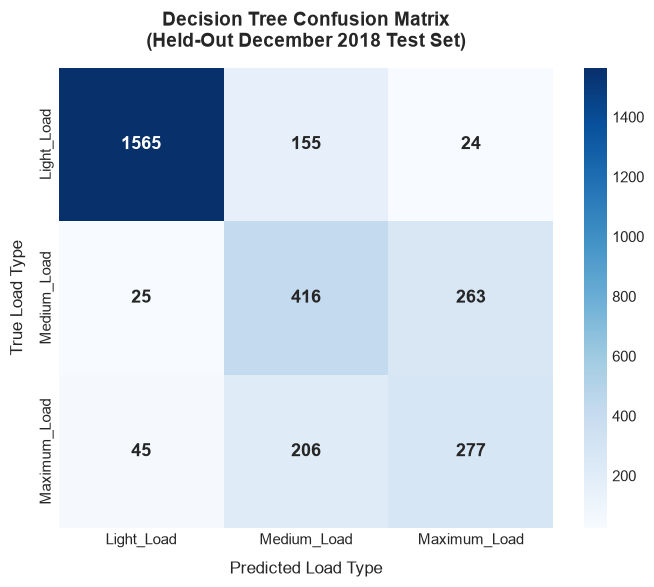

In [23]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, dt_pred, labels=labels_order)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order,
            cbar=True, ax=ax, annot_kws={"size": 13, "weight": "bold"})

ax.set_title("Decision Tree Confusion Matrix\n(Held-Out December 2018 Test Set)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Load Type", fontsize=12, labelpad=10)
ax.set_ylabel("True Load Type", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()


**Confusion Matrix Interpretation**:
- **`Light_Load`**: Extremely well classified ($1,565$ out of $1,744$ correct, $89.7\%$ recall, $95.7\%$ precision).
- **`Medium_Load`**: $416$ out of $704$ correct ($59.1\%$ recall). The primary misclassifications ($263$ instances) were confused with `Maximum_Load`.
- **`Maximum_Load`**: $277$ out of $528$ correct ($52.5\%$ recall). Misclassifications were predominantly predicted as `Medium_Load` ($206$ instances).
- The model cleanly separates off-peak periods (`Light_Load`) from active periods, while distinguishing between `Medium_Load` and `Maximum_Load` represents the main boundary challenge.


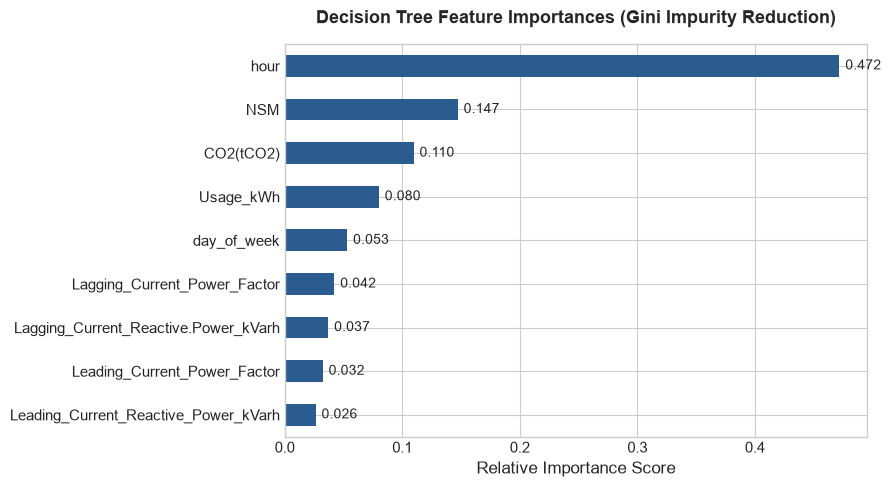

In [24]:
# Feature Importances Plot
feat_importances = pd.Series(dt_clf.feature_importances_, index=feature_columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
feat_importances.plot(kind='barh', color='#2b5c8f', ax=ax)

ax.set_title("Decision Tree Feature Importances (Gini Impurity Reduction)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Relative Importance Score", fontsize=12)
for p in ax.patches:
    ax.annotate(f"{p.get_width():.3f}",
                (p.get_width() + 0.005, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10)
plt.tight_layout()
plt.show()


**Feature Importance Interpretation**:
- **`hour`** is the single most decisive feature ($47.2\%$ importance), followed by **`NSM`** ($14.7\%$).
- Together, time-of-day features contribute over $60\%$ of the decision criteria, consistent with fixed industrial operational shifts.
- **`CO2(tCO2)`** ($11.0\%$) and **`Usage_kWh`** ($8.0\%$) provide the primary physical consumption signals.


## Section 10 — Results and Conclusion

### 10.1 Model Performance Summary
- **Decision Tree Accuracy**: **75.87%** on the held-out December test set.
- **Macro F1-Score**: **66.51%** (Macro Precision: 66.12%, Macro Recall: 67.10%).
- **Comparison with Baseline**: The naive `DummyClassifier` achieved 58.60% accuracy by always guessing `Light_Load`, but had an unacceptable Macro F1 of **24.63%** because it completely failed on both Medium and Maximum load classes. The Decision Tree demonstrates significant learning and practical utility.

### 10.2 Strengths
- **Superior Light Load Detection**: Identifies low-demand hours with 95.72% precision and 89.74% recall.
- **Explainability**: Decision tree splits provide intuitive, human-interpretable threshold rules that power engineers can easily audit.
- **Zero Data Leakage**: The model was evaluated strictly on chronological future data with train-only median imputation.

### 10.3 Challenges and Limitations
- **Medium vs. Maximum Load Boundary**: Both classes occur during midday manufacturing hours and exhibit overlapping energy consumption levels, leading to mutual confusion.
- **Seasonality**: December represents winter operating conditions. Energy demand in December may reflect heating demands or year-end production slowdowns that differ from summer months.
- **Sensor Counter Drift**: Raw `NSM` values in historical sensor feeds suffered from clock overflow/noise, highlighting the importance of engineering robust time features from verified timestamps.


## Section 11 — How to Run the Notebook

### Reproducibility Guide:
1. **Environment Setup**:
   Clone or navigate to the assignment repository:
   ```bash
   cd ass-2ur
   ```
2. **Create and Activate Virtual Environment**:
   ```bash
   python -m venv .venv
   # Windows PowerShell:
   .\.venv\Scripts\Activate.ps1
   # Linux / macOS:
   source .venv/bin/activate
   ```
3. **Install Required Packages**:
   ```bash
   pip install -r requirements.txt
   ```
4. **Launch Jupyter**:
   ```bash
   jupyter notebook
   ```
5. **Execute Notebook**:
   Open `Load_Type_Prediction.ipynb` and select **Kernel -> Restart & Run All**. Every cell executes sequentially from top to bottom without errors.
